In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Jupyter kernel is working!")

Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Python executable: e:\ML\mini project 1\venv\Scripts\python.exe
Jupyter kernel is working!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from pathlib import Path

project_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

df = pd.read_csv(project_path / "dataset" / "cleaned_reviews.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (32940, 5)


,review_id,reviewer_id,review_title,review_text,label
0,R36G7QSYO7QRAS,AFP3AD7L3KWYHHQ4UQAIWJAZX7FQ,Cut pvc like fruit.,", Your browser does not support HTML5 video...",1
1,R1CM6Y3BKQGPSE,AH74ZCS65PTXJHOWW46XQUKY46GA,Super easy to use,Got this to cut the pipe behind toilet that wa...,1
2,R3LVQ4CXB7F53U,AFJEFSALLQGG3EU3MQTHYE2Y4RRA,Good quality,Light is very well packaged to protect it du...,1
3,R335LSATNIQJU2,AFNNVBDJ4ANOWPI46VII6OGJHSAA,geow light,I am using this for my aquarium. The light i...,1
4,R158OPLKCB175R,AFP3AD7L3KWYHHQ4UQAIWJAZX7FQ,Awesome unit.,", Your browser does not support HTML5 video...",1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32940 entries, 0 to 32939
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   review_id     32940 non-null  str  
 1   reviewer_id   32940 non-null  str  
 2   review_title  32679 non-null  str  
 3   review_text   32940 non-null  str  
 4   label         32940 non-null  int64
dtypes: int64(1), str(4)
memory usage: 12.2 MB


In [5]:
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
review_id         0
reviewer_id       0
review_title    261
review_text       0
label             0
dtype: int64


In [6]:
print("Duplicate review IDs:", df["review_id"].duplicated().sum())

Duplicate review IDs: 0


In [7]:
print("Label distribution:")
print(df["label"].value_counts())

print("\nPercentage distribution:")
print(df["label"].value_counts(normalize=True) * 100)

Label distribution:
label
1    22138
0    10802
Name: count, dtype: int64

Percentage distribution:
label
1    67.207043
0    32.792957
Name: proportion, dtype: float64


In [9]:
from pathlib import Path

project_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

output_path = project_path / "outputs"

output_path.mkdir(exist_ok=True)

print("Output folder:", output_path)

Output folder: e:\ML\mini project 1\outputs


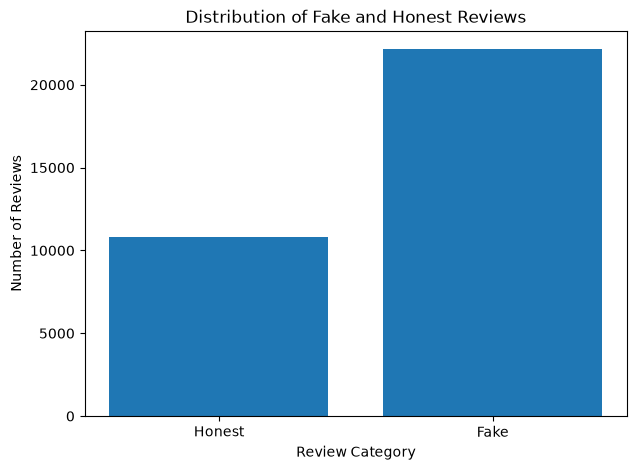

In [10]:
# Count reviews in each category
label_counts = df["label"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    ["Honest", "Fake"],
    [label_counts[0], label_counts[1]]
)

plt.title("Distribution of Fake and Honest Reviews")
plt.xlabel("Review Category")
plt.ylabel("Number of Reviews")

plt.savefig(output_path / "label_distribution.png")
plt.show()

In [11]:
# Calculate the number of words in each review
df["review_length"] = df["review_text"].str.split().str.len()

# Display first five results
df[["review_text", "review_length", "label"]].head()

,review_text,review_length,label
0,", Your browser does not support HTML5 video...",99,1
1,Got this to cut the pipe behind toilet that wa...,24,1
2,Light is very well packaged to protect it du...,76,1
3,I am using this for my aquarium. The light i...,47,1
4,", Your browser does not support HTML5 video...",141,1


In [12]:
# Calculate review length statistics
print(df["review_length"].describe())

count    32940.000000
mean        53.348452
std         55.156820
min          1.000000
25%         21.000000
50%         41.000000
75%         68.000000
max       2501.000000
Name: review_length, dtype: float64


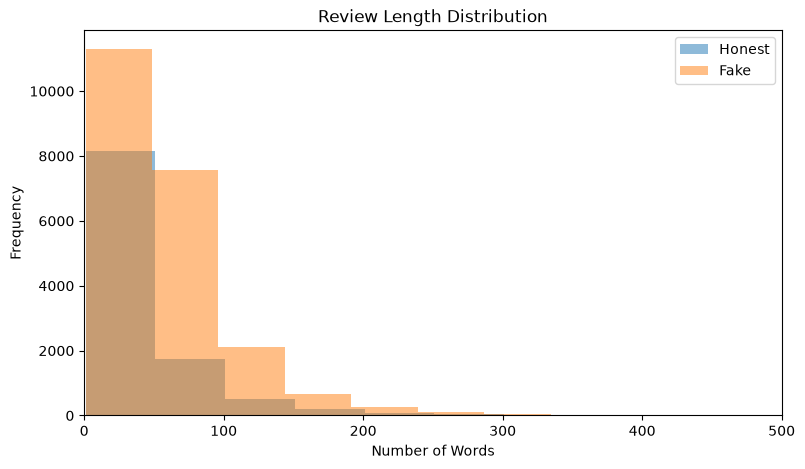

In [13]:
plt.figure(figsize=(9, 5))

for label, name in [(0, "Honest"), (1, "Fake")]:
    plt.hist(
        df.loc[df["label"] == label, "review_length"],
        bins=50,
        alpha=0.5,
        label=name
    )

plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.xlim(0, 500)
plt.legend()

plt.savefig(output_path / "review_length.png")
plt.show()

In [14]:
# Compare review lengths by label
review_stats = df.groupby("label")["review_length"].agg(
    ["mean", "median", "min", "max"]
)

review_stats.index = ["Honest", "Fake"]

print(review_stats)

             mean  median  min   max
Honest  40.326606    24.0    1  2501
Fake    59.702322    48.0    1  2382


<Figure size 800x500 with 0 Axes>

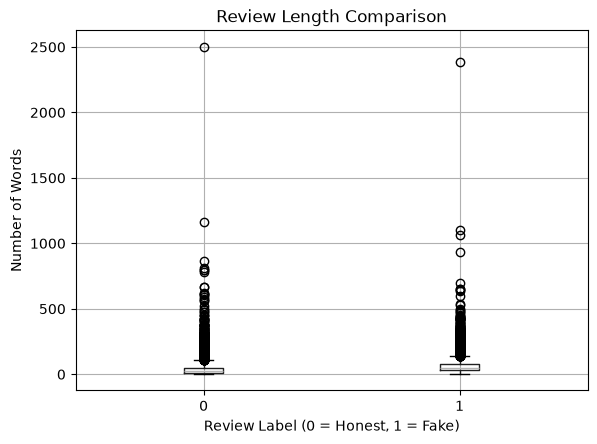

In [15]:
plt.figure(figsize=(8, 5))

df.boxplot(column="review_length", by="label")

plt.title("Review Length Comparison")
plt.suptitle("")
plt.xlabel("Review Label (0 = Honest, 1 = Fake)")
plt.ylabel("Number of Words")

plt.savefig(output_path / "review_length_comparison.png")
plt.show()

In [16]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20
)

word_matrix = vectorizer.fit_transform(df["review_text"])

word_counts = word_matrix.sum(axis=0).A1
words = vectorizer.get_feature_names_out()

word_frequency = pd.DataFrame({
    "Word": words,
    "Frequency": word_counts
}).sort_values("Frequency", ascending=False)

print(word_frequency)

       Word  Frequency
15      use      11513
4     great      10554
2      easy      10050
3      good       8276
7      like       7532
13   really       6334
5      just       5707
9      love       5510
11  product       5088
19    works       4864
14     time       4572
6     light       4358
12  quality       4251
10     nice       4097
16     used       3592
8    little       3402
17    using       3345
18     work       3343
0    bought       3079
1      does       3051


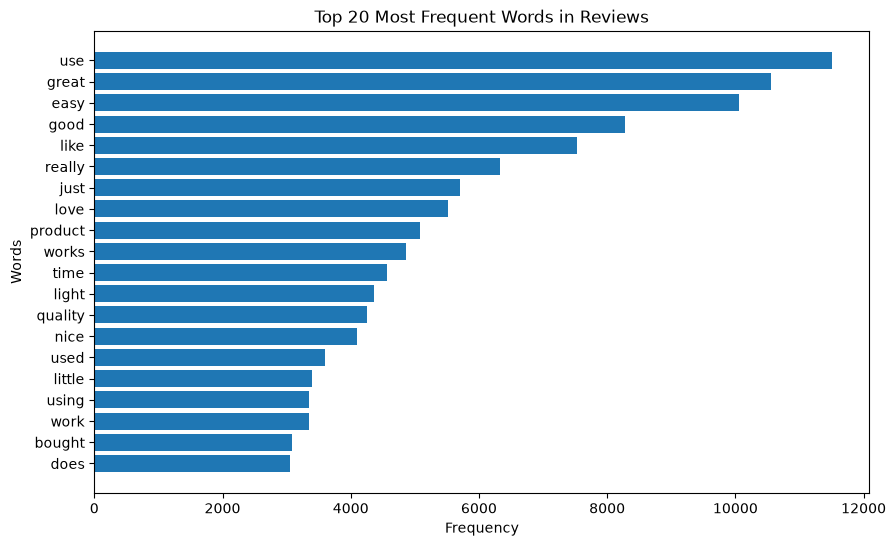

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    word_frequency["Word"][::-1],
    word_frequency["Frequency"][::-1]
)

plt.title("Top 20 Most Frequent Words in Reviews")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.savefig(output_path / "top_words.png")
plt.show()

In [18]:
print("EDA SUMMARY")
print("----------------------")

print("Total reviews:", len(df))
print("Fake-labelled reviews:", (df["label"] == 1).sum())
print("Honest-labelled reviews:", (df["label"] == 0).sum())

print("Average review length:", round(df["review_length"].mean(), 2))
print("Median review length:", df["review_length"].median())

print("\nEDA completed successfully!")

EDA SUMMARY
----------------------
Total reviews: 32940
Fake-labelled reviews: 22138
Honest-labelled reviews: 10802
Average review length: 53.35
Median review length: 41.0

EDA completed successfully!
